# Etapa 2 — Limpeza e Preparação dos Dados

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Verificar inconsistências, corrigir tipos de dados e criar features derivadas que serão usadas nas etapas de modelagem.

---

## 1. Carregamento dos Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('data/base_cadeia_suprimentos.csv')
ref_produtos     = pd.read_csv('data/ref_produtos.csv')
ref_fornecedores = pd.read_csv('data/ref_fornecedores.csv')

print(f'Shape original: {df.shape}')
df.head(3)

Shape original: (4406, 31)


,id_pedido,data_pedido,ano,mes,trimestre,id_produto,produto,categoria,giro_produto,id_fornecedor,...,status_entrega,estoque_disponivel,estoque_minimo,estoque_maximo,ruptura_estoque,custo_frete,custo_armazenagem,prazo_pagamento_dias,regiao_destino,estado_destino
0,PED000001,2022-01-03,2022,1,1,P07,Capacete de Seguranca,EPI,alto,F04,...,No Prazo,759,600,2000,0,62.87,31.10,25,Sudeste,SP
1,PED000002,2022-01-03,2022,1,1,P07,Capacete de Seguranca,EPI,alto,F09,...,No Prazo,923,600,2000,0,182.51,53.11,60,Nordeste,BA
2,PED000003,2022-01-04,2022,1,1,P08,Cabo Flexivel,Eletroeletronicos,alto,F04,...,No Prazo,1222,360,1200,0,28.15,12.64,30,Sudeste,SP


## 2. Verificação de Qualidade dos Dados

In [2]:
# --- 2.1 Valores nulos ---
nulos = df.isnull().sum()
print('Colunas com valores nulos:')
print(nulos[nulos > 0].to_string() if nulos.sum() > 0 else '  Nenhum valor nulo encontrado.')

Colunas com valores nulos:
  Nenhum valor nulo encontrado.


In [3]:
# --- 2.2 Duplicatas ---
dup = df.duplicated(subset='id_pedido').sum()
print(f'Pedidos duplicados: {dup}')

Pedidos duplicados: 0


In [4]:
# --- 2.3 Consistência de valores categóricos ---
for col in ['categoria', 'tipo_fornecedor', 'giro_produto', 'status_entrega']:
    print(f'{col}: {sorted(df[col].unique())}')

categoria: ['EPI', 'Eletroeletronicos', 'Ferramentas', 'Fixadores', 'Manutencao', 'Materiais']
tipo_fornecedor: ['internacional', 'nacional', 'regional']
giro_produto: ['alto', 'baixo', 'medio']
status_entrega: ['Atrasado', 'No Prazo']


In [5]:
# --- 2.4 Verificar se data_entrega_real >= data_pedido ---
df_temp = df.copy()
df_temp['data_pedido']       = pd.to_datetime(df_temp['data_pedido'])
df_temp['data_entrega_real'] = pd.to_datetime(df_temp['data_entrega_real'])

invalidos = (df_temp['data_entrega_real'] < df_temp['data_pedido']).sum()
print(f'Registros com data_entrega_real < data_pedido: {invalidos}')

# Verificar se atraso_dias é coerente
df_temp['data_entrega_prevista'] = pd.to_datetime(df_temp['data_entrega_prevista'])
df_temp['atraso_calc'] = (df_temp['data_entrega_real'] - df_temp['data_entrega_prevista']).dt.days.clip(lower=0)
diff_atraso = (df_temp['atraso_calc'] != df_temp['atraso_dias']).sum()
print(f'Divergências em atraso_dias: {diff_atraso}')

Registros com data_entrega_real < data_pedido: 0
Divergências em atraso_dias: 983


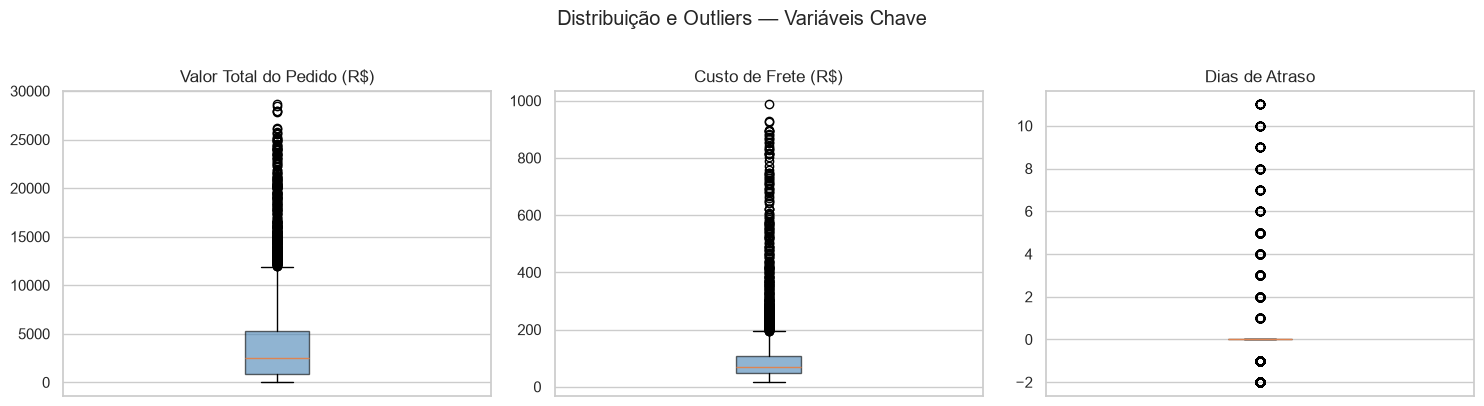

In [6]:
# --- 2.5 Outliers em variáveis numéricas chave ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cols_box = ['valor_total_pedido', 'custo_frete', 'atraso_dias']
titulos  = ['Valor Total do Pedido (R$)', 'Custo de Frete (R$)', 'Dias de Atraso']

for ax, col, titulo in zip(axes, cols_box, titulos):
    ax.boxplot(df[col].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor='steelblue', alpha=0.6))
    ax.set_title(titulo)
    ax.set_xticks([])

plt.suptitle('Distribuição e Outliers — Variáveis Chave', y=1.01)
plt.tight_layout()
plt.show()

## 3. Conversão de Tipos

In [7]:
df['data_pedido']           = pd.to_datetime(df['data_pedido'])
df['data_entrega_prevista'] = pd.to_datetime(df['data_entrega_prevista'])
df['data_entrega_real']     = pd.to_datetime(df['data_entrega_real'])

# ruptura_estoque como booleano
if df['ruptura_estoque'].dtype == object:
    df['ruptura_estoque'] = df['ruptura_estoque'].map({'True': True, 'False': False, True: True, False: False})
df['ruptura_estoque'] = df['ruptura_estoque'].astype(bool)

print('Tipos após conversão:')
print(df[['data_pedido','data_entrega_real','ruptura_estoque']].dtypes)

Tipos após conversão:
data_pedido          datetime64[us]
data_entrega_real    datetime64[us]
ruptura_estoque                bool
dtype: object


## 4. Criação de Features Derivadas

In [8]:
# --- 4.1 lead_time_real: dias entre pedido e entrega efetiva ---
df['lead_time_real'] = (df['data_entrega_real'] - df['data_pedido']).dt.days

# --- 4.2 custo_total_pedido: valor + frete + armazenagem ---
df['custo_total_pedido'] = df['valor_total_pedido'] + df['custo_frete'] + df['custo_armazenagem']

# --- 4.3 ruptura_real: flag binária ---
df['ruptura_real'] = (df['quantidade_pedida'] > df['estoque_disponivel']).astype(int)

# --- 4.3 demanda_media_diaria por produto (estimada sobre todo o histórico) ---
# Total de dias no período
dias_periodo = (df['data_pedido'].max() - df['data_pedido'].min()).days + 1
demanda_media = (
    df.groupby('id_produto')['quantidade_pedida']
    .sum()
    .div(dias_periodo)
    .reset_index()
    .rename(columns={'quantidade_pedida': 'demanda_media_diaria'})
)
df = df.merge(demanda_media, on='id_produto', how='left')

# --- 4.4 cobertura_estoque: dias que o estoque atual aguenta ---
df['cobertura_estoque'] = df['estoque_disponivel'] / df['demanda_media_diaria'].replace(0, np.nan)
df['cobertura_estoque'] = df['cobertura_estoque'].clip(upper=365)  # limitar a 1 ano

# --- 4.5 entrega_no_prazo: flag binária ---
df['entrega_no_prazo'] = (df['status_entrega'] == 'No Prazo').astype(int)

# --- 4.6 indice_servico_fornecedor: OTIF por fornecedor ---
otif_forn = (
    df.groupby('id_fornecedor')['entrega_no_prazo']
    .mean()
    .reset_index()
    .rename(columns={'entrega_no_prazo': 'indice_servico_fornecedor'})
)
df = df.merge(otif_forn, on='id_fornecedor', how='left')

print('Features derivadas criadas com sucesso!')
print(df[['lead_time_real', 'custo_total_pedido', 'cobertura_estoque',
          'entrega_no_prazo', 'indice_servico_fornecedor']].describe().round(2))

Features derivadas criadas com sucesso!
       lead_time_real  custo_total_pedido  cobertura_estoque  \
count         4406.00             4406.00            4406.00   
mean            12.00             4281.48             285.20   
std             12.51             4878.45             116.40   
min              1.00               44.62               1.51   
25%              4.00              969.32             213.12   
50%              6.00             2592.52             365.00   
75%             15.00             5526.77             365.00   
max             56.00            29262.91             365.00   

       entrega_no_prazo  indice_servico_fornecedor  
count           4406.00                    4406.00  
mean               0.89                       0.89  
std                0.31                       0.06  
min                0.00                       0.59  
25%                1.00                       0.88  
50%                1.00                       0.92  
75%         

## 5. Codificação de Variáveis Categóricas

In [9]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

# Label Encoding para variáveis de baixa cardinalidade
le = LabelEncoder()
cols_label = ['categoria', 'giro_produto', 'tipo_fornecedor']
for col in cols_label:
    df_model[col + '_enc'] = le.fit_transform(df_model[col])

# One-Hot Encoding para region
df_model = pd.get_dummies(df_model, columns=['regiao_destino'], prefix='regiao', drop_first=True)

print('Colunas após encoding:', [c for c in df_model.columns if '_enc' in c or 'regiao_' in c])

Colunas após encoding: ['categoria_enc', 'giro_produto_enc', 'tipo_fornecedor_enc', 'regiao_Nordeste', 'regiao_Norte', 'regiao_Sudeste', 'regiao_Sul']


## 6. Validação e Exportação da Base Tratada

In [10]:
print(f'Shape final: {df.shape}')
print(f'Nulos restantes: {df.isnull().sum().sum()}')
print('\nPrimeiras linhas com as novas features:')
display(df[['id_pedido', 'id_produto', 'lead_time_real', 'custo_total_pedido',
             'cobertura_estoque', 'indice_servico_fornecedor']].head(5))

# Salvar base tratada para uso nas próximas etapas
df.to_csv('data/base_tratada.csv', index=False)
print('\nBase tratada salva em: data/base_tratada.csv')

Shape final: (4406, 38)
Nulos restantes: 0

Primeiras linhas com as novas features:


,id_pedido,id_produto,lead_time_real,custo_total_pedido,cobertura_estoque,indice_servico_fornecedor
0,PED000001,P07,3,2929.04,9.497266,0.884041
1,PED000002,P07,42,3997.38,11.549377,0.887379
2,PED000003,P08,5,750.87,22.175798,0.884041
3,PED000004,P04,5,7691.84,17.158704,0.947902
4,PED000005,P07,3,13625.53,15.190621,0.884041



Base tratada salva em: data/base_tratada.csv


## 7. Resumo das Transformações

| Feature | Fórmula / Lógica | Propósito |
|---|---|---|
| `lead_time_real` | `data_entrega_real - data_pedido` (dias) | Medir tempo real de fornecimento |
| `custo_total_pedido` | `valor_total + frete + armazenagem` | Custo completo por pedido |
| `ruptura_real` | `quantidade_pedida > estoque_disponivel` | Flag binária de ruptura efetiva do pedido |
| `demanda_media_diaria` | `qtd_total / dias_período` por produto | Base para cálculo de cobertura |
| `cobertura_estoque` | `estoque_disponivel / demanda_media_diaria` | Dias de autonomia sem reposição |
| `entrega_no_prazo` | `status_entrega == 'No Prazo'` | Flag binária para OTIF |
| `indice_servico_fornecedor` | Média de `entrega_no_prazo` por fornecedor | Nível de serviço histórico |

> **Próxima etapa:** Análise de Desempenho de Fornecedores (Etapa 3).